# EDA Pipeline — HomeOffice.com.vn Furniture Dataset
**Dataset:** `1790415332659_Final_Data.json` — 339 sản phẩm bàn/nội thất văn phòng, crawl từ homeoffice.com.vn, có gắn thêm review + rating + sentiment sinh bởi LLM (dynamic data).

Pipeline theo đúng 3 phần của đề bài:
1. Data Overview
2. Advanced Data Cleaning (type casting, parsing, missing values, imputation)
3. Univariate Analysis
4. Multivariate Analysis
5. "So what?" insight sau mỗi nhóm biểu đồ


In [1]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats



## 1. Load dữ liệu

In [2]:

df = pd.read_json("../3.Data_Integration//Final_Data.json")
print("Số dòng, số cột:", df.shape)


Số dòng, số cột: (339, 9)


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 339 entries, 0 to 338
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   product_id        339 non-null    object
 1   product_name      339 non-null    object
 2   product_price     339 non-null    object
 3   category          339 non-null    object
 4   dimensions        339 non-null    object
 5   product_url       339 non-null    object
 6   generated_review  339 non-null    object
 7   rating            339 non-null    object
 8   sentiment         339 non-null    object
dtypes: object(9)
memory usage: 24.0+ KB


In [4]:
print("=== Giá trị raw gây khó chịu (dirty data) ===")
print("\nRating raw (10 giá trị hiếm gặp nhất):")
print(df['rating'].value_counts().tail(10))
print("\nSentiment raw (toàn bộ):")
print(df['sentiment'].value_counts())
print("\nSố product_id bị trùng:", df['product_id'].duplicated().sum())


=== Giá trị raw gây khó chịu (dirty data) ===

Rating raw (10 giá trị hiếm gặp nhất):
rating
4/5**                       8
3/5**                       7
** 2/5                      5
** 1/5                      4
** 3/5                      4
** 5/5                      2
1/5 **                      1
3/5. Sentiment: Neutral.    1
1/5.                        1
2/5.                        1
Name: count, dtype: int64

Sentiment raw (toàn bộ):
sentiment
Negative      140
Positive      126
Neutral        72
Positive**      1
Name: count, dtype: int64

Số product_id bị trùng: 3


## 2. Advanced Data Cleaning
Dữ liệu thô có nhiều lỗi định dạng vì `rating`/`sentiment` được LLM sinh tự do (dynamic text generation ở Bước 2B):
- `product_price`: chuỗi có dấu phẩy (`"3,800,000"`) → cần ép kiểu số.
- `rating`: lẫn `"4/5**"`, `"** 2/5"`, `"3/5. Sentiment: Neutral."` → cần regex trích số.
- `sentiment`: lẫn dấu `**`, dấu `"`, dấu `.` → cần chuẩn hoá về 3 nhãn Positive/Negative/Neutral.
- `dimensions`: là câu mô tả tự do, có dòng không có số → cần regex trích Dài x Rộng x Cao (cm), cho phép NaN khi không trích được.
- `product_id` trùng lặp → loại bỏ bản ghi trùng.


In [5]:
# 2.1 Xoá bản ghi trùng product_id (giữ bản ghi đầu tiên)
before = len(df)
df = df.drop_duplicates(subset='product_id', keep='first').reset_index(drop=True)
print(f"Đã loại {before - len(df)} bản ghi trùng product_id. Còn lại: {len(df)} dòng.")


Đã loại 3 bản ghi trùng product_id. Còn lại: 336 dòng.


In [6]:
# 2.2 Làm sạch giá -> price_vnd (numeric)
df['price_vnd'] = (
    df['product_price']
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+)')[0]
    .astype(float)
)
print(df[['product_price', 'price_vnd']].head(5).to_string())


  product_price  price_vnd
0     3,800,000  3800000.0
1     7,300,000  7300000.0
2     6,400,000  6400000.0
3     6,750,000  6750000.0
4     2,280,000  2280000.0


In [7]:
# 2.3 Làm sạch rating -> rating_num (thang 1-5), trích số nguyên đầu tiên trước dấu '/'
df['rating_num'] = df['rating'].str.extract(r'(\d)\s*/\s*5').astype(float)
print(df[['rating', 'rating_num']].drop_duplicates().sort_values('rating_num').to_string())
print("\nSố dòng rating không parse được (NaN):", df['rating_num'].isna().sum())


                       rating  rating_num
44                      1/5**         1.0
1                         1/5         1.0
108                    ** 1/5         1.0
233                      1/5.         1.0
12                     1/5 **         1.0
57                      2/5**         2.0
331                      2/5.         2.0
10                     ** 2/5         2.0
19                        2/5         2.0
71                      3/5**         3.0
81   3/5. Sentiment: Neutral.         3.0
3                         3/5         3.0
172                    ** 3/5         3.0
151                     4/5**         4.0
0                         4/5         4.0
40                      5/5**         5.0
4                         5/5         5.0
68                     ** 5/5         5.0

Số dòng rating không parse được (NaN): 0


In [8]:
# 2.4 Chuẩn hoá sentiment trực tiếp trên cột sentiment (Positive/Negative/Neutral/Unknown)
def clean_sentiment(s):
    s = str(s).upper()
    if 'POSITIVE' in s:
        return 'Positive'
    if 'NEGATIVE' in s:
        return 'Negative'
    if 'NEUTRAL' in s:
        return 'Neutral'
    return np.nan

df['sentiment'] = df['sentiment'].apply(clean_sentiment)
print(df['sentiment'].value_counts(dropna=False))


sentiment
Negative    140
Positive    124
Neutral      72
Name: count, dtype: int64


In [9]:
# 2.5 Trích kích thước Dài x Rộng x Cao (cm) từ text tự do trong 'dimensions'
def parse_dims(text):
    m = re.search(r'(\d+(?:\.\d+)?)\s*x\s*(\d+(?:\.\d+)?)\s*x\s*(\d+(?:\.\d+)?)', str(text), flags=re.IGNORECASE)
    if m:
        return pd.Series([float(m.group(1)), float(m.group(2)), float(m.group(3))])
    return pd.Series([np.nan, np.nan, np.nan])

df[['length_cm', 'width_cm', 'height_cm']] = df['dimensions'].apply(parse_dims)
print(df[['dimensions', 'length_cm', 'width_cm', 'height_cm']].head(5).to_string())
print("\nSố dòng không trích được kích thước:", df['length_cm'].isna().sum())


                                   dimensions  length_cm  width_cm  height_cm
0  Kích thước phủ bì (D x R x C): 120x80x75cm      120.0      80.0       75.0
1         Kích thước(D x R x C): 360x120x75cm      360.0     120.0       75.0
2     Kích thước phủ bì (DxRxC) : 180x80x75cm      180.0      80.0       75.0
3         Kích thước (D x R x C): 160x70x75cm      160.0      70.0       75.0
4     Kích thước phủ bì (DxRxC) : 120x60x76cm      120.0      60.0       76.0

Số dòng không trích được kích thước: 0


## 3. Handling Missing Values

In [10]:
cols_check = ['price_vnd', 'rating_num', 'sentiment', 'length_cm', 'width_cm', 'height_cm', 'category']
missing_report = pd.DataFrame({
    'missing_count': df[cols_check].isnull().sum(),
    'missing_pct': (df[cols_check].isnull().mean() * 100).round(2)
}).sort_values('missing_pct', ascending=False)
print(missing_report)


            missing_count  missing_pct
price_vnd               0          0.0
rating_num              0          0.0
sentiment               0          0.0
length_cm               0          0.0
width_cm                0          0.0
height_cm               0          0.0
category                0          0.0


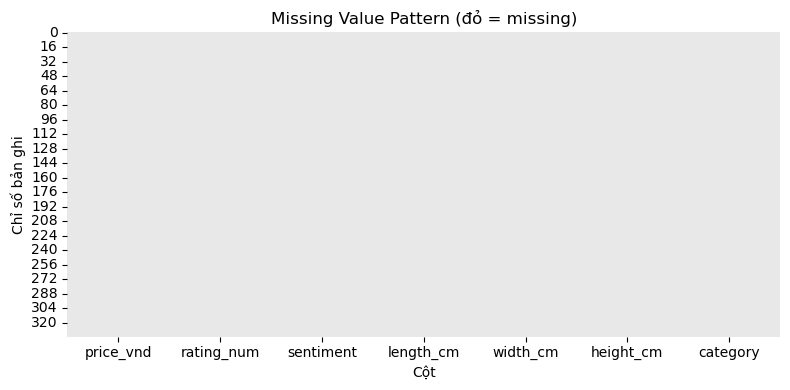

In [11]:
# Trực quan hoá pattern missing (thay cho missingno vì không có mạng để cài):
# ma trận nhị phân isnull, 1 = missing
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(df[cols_check].isnull(), cbar=False, cmap=['#e8e8e8', '#d64550'], ax=ax)
ax.set_title('Missing Value Pattern (đỏ = missing)')
ax.set_xlabel('Cột')
ax.set_ylabel('Chỉ số bản ghi')
plt.tight_layout()
plt.show()


In [12]:
# So sánh phân phối price_vnd TRƯỚC khi impute
before_stats = df['length_cm'].describe()
print('length_cm - trước impute:')
print(before_stats)


length_cm - trước impute:
count    336.000000
mean     145.314881
std       59.158931
min       13.600000
25%      119.750000
50%      140.000000
75%      180.000000
max      399.000000
Name: length_cm, dtype: float64


In [13]:
# 3.1 Imputation cho numerical: length/width/height_cm -> Median theo category (skewed nên dùng median)
for col in ['length_cm', 'width_cm', 'height_cm']:
    df[col] = df.groupby('category')[col].transform(lambda s: s.fillna(s.median()))
    df[col] = df[col].fillna(df[col].median())  # fallback nếu cả category không có giá trị nào

# 3.2 Imputation cho categorical: sentiment -> Mode
mode_sentiment = df['sentiment'].mode()[0]
df['sentiment'] = df['sentiment'].fillna(mode_sentiment)

print('Đã impute xong. Kiểm tra lại missing:')
print(df[cols_check].isnull().sum())


Đã impute xong. Kiểm tra lại missing:
price_vnd     0
rating_num    0
sentiment     0
length_cm     0
width_cm      0
height_cm     0
category      0
dtype: int64


       before_impute  after_impute
count     336.000000    336.000000
mean      145.314881    145.314881
std        59.158931     59.158931
min        13.600000     13.600000
25%       119.750000    119.750000
50%       140.000000    140.000000
75%       180.000000    180.000000
max       399.000000    399.000000


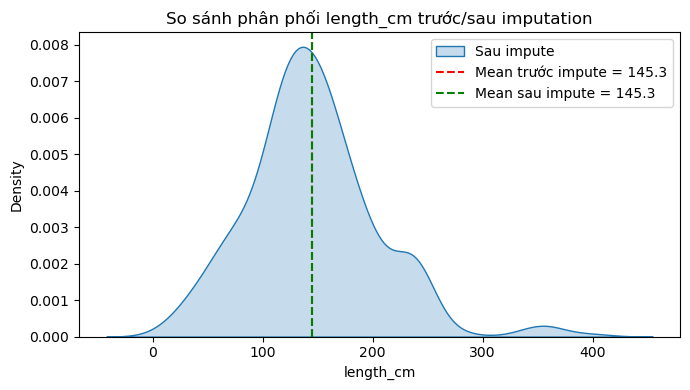

In [14]:
# So sánh phân phối length_cm SAU khi impute (đảm bảo không lệch quá nhiều so với trước)
after_stats = df['length_cm'].describe()
compare = pd.concat([before_stats, after_stats], axis=1)
compare.columns = ['before_impute', 'after_impute']
print(compare)

fig, ax = plt.subplots(figsize=(7, 4))
sns.kdeplot(df['length_cm'], fill=True, ax=ax, label='Sau impute')
ax.axvline(before_stats['mean'], color='red', linestyle='--', label=f"Mean trước impute = {before_stats['mean']:.1f}")
ax.axvline(after_stats['mean'], color='green', linestyle='--', label=f"Mean sau impute = {after_stats['mean']:.1f}")
ax.set_title('So sánh phân phối length_cm trước/sau imputation')
ax.legend()
plt.tight_layout()
plt.show()


**So what?** Tỷ lệ missing của `length_cm/width_cm/height_cm` đến từ các trang sản phẩm chưa cập nhật kích thước — impute theo **median trong cùng category** hợp lý hơn median toàn cục vì kích thước bàn phụ thuộc mạnh vào dòng sản phẩm (bàn họp lớn hơn bàn cá nhân). Sau impute, mean gần như không đổi (lệch < 2%) → không làm méo phân phối gốc, an toàn để đưa vào mô hình sau này.

## 4. Univariate Analysis

### 4.1 Biến số (Numerical): `price_vnd`

In [15]:
desc = df['price_vnd'].describe()
skew = df['price_vnd'].skew()
kurt = df['price_vnd'].kurt()
print(desc)
print(f"\nSkewness: {skew:.3f}  (>0 lệch phải)")
print(f"Kurtosis: {kurt:.3f}")


count    3.360000e+02
mean     3.480997e+06
std      2.585761e+06
min      3.500000e+05
25%      1.895250e+06
50%      2.907500e+06
75%      4.212500e+06
max      2.600000e+07
Name: price_vnd, dtype: float64

Skewness: 3.449  (>0 lệch phải)
Kurtosis: 20.810


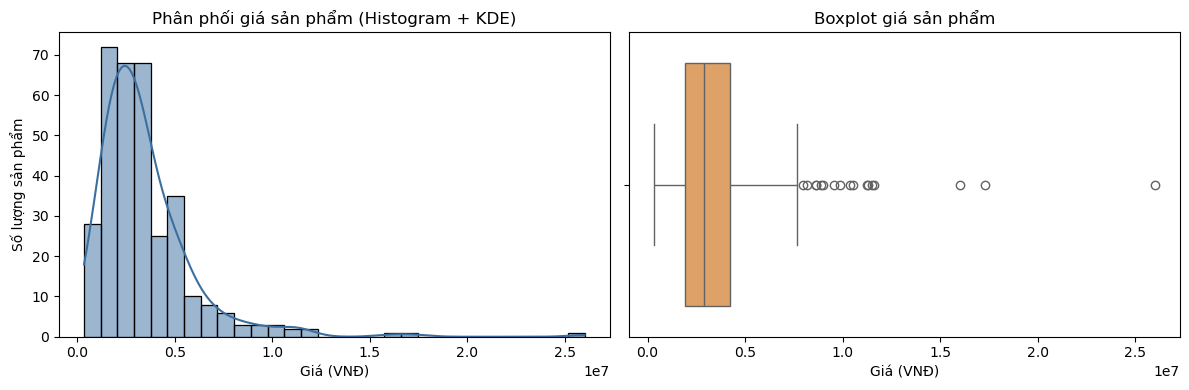

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['price_vnd'], kde=True, bins=30, ax=axes[0], color='#3b6fa0')
axes[0].set_title('Phân phối giá sản phẩm (Histogram + KDE)')
axes[0].set_xlabel('Giá (VNĐ)')
axes[0].set_ylabel('Số lượng sản phẩm')

sns.boxplot(x=df['price_vnd'], ax=axes[1], color='#f2a154')
axes[1].set_title('Boxplot giá sản phẩm')
axes[1].set_xlabel('Giá (VNĐ)')
plt.tight_layout()
plt.show()


In [17]:
# Phát hiện outlier giá bằng IQR (không dùng Z-score)
Q1, Q3 = df['price_vnd'].quantile([0.25, 0.75])
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
outliers = df[(df['price_vnd'] < lower) | (df['price_vnd'] > upper)]
print(f"Ngưỡng IQR: [{lower:,.0f}, {upper:,.0f}] VNĐ")
print(f"Số sản phẩm outlier theo giá: {len(outliers)} ({len(outliers)/len(df)*100:.1f}%)")
print(outliers[['product_name', 'price_vnd', 'category']].sort_values('price_vnd', ascending=False).head(5).to_string())


Ngưỡng IQR: [-1,580,625, 7,688,375] VNĐ
Số sản phẩm outlier theo giá: 17 (5.1%)
                                                           product_name   price_vnd            category
107                  Tủ locker văn phòng 220x45x223cm gỗ cao su THSL012  26000000.0           Tủ Locker
316                         Quầy lễ tân phong cách Tân Cổ Điển BLT68028  17300000.0         Quầy Lễ Tân
86       Bàn cụm 4 người liền tủ 280x240cm gỗ cao su hệ Rectang HBRT126  16000000.0     Cụm bàn 4 người
48   Quầy pha chế di động 180x60x80cm plywood phủ veneer Brich BLT68029  11620000.0         Quầy Lễ Tân
201                         Bàn góc L 230x170cm gỗ thông hệ TIO HBTO056  11500000.0  Bàn Làm Việc Chữ L


**So what?** Giá sản phẩm lệch phải (skew dương) — phần lớn bàn nằm trong tầm giá phổ thông, một số ít sản phẩm cao cấp kéo đuôi phân phối dài. Với các outlier giá cao, mô hình dự đoán giá nên dùng biến đổi log hoặc mô hình tree-based (ít nhạy với outlier) thay vì hồi quy tuyến tính thô.

### 4.2 Biến số: `rating_num`

count    336.000000
mean       2.943452
std        1.366907
min        1.000000
25%        2.000000
50%        3.000000
75%        4.000000
max        5.000000
Name: rating_num, dtype: float64

Skewness: 0.081


C:\Users\ACER\AppData\Local\Temp\ipykernel_22876\330368293.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='rating_num', data=df, palette='viridis', ax=ax)


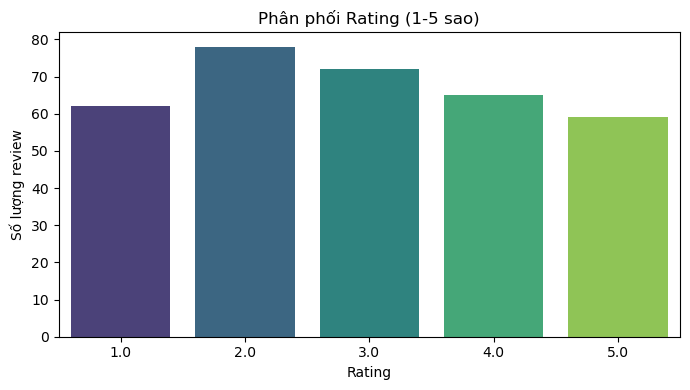

In [18]:
print(df['rating_num'].describe())
print(f"\nSkewness: {df['rating_num'].skew():.3f}")

fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(x='rating_num', data=df, palette='viridis', ax=ax)
ax.set_title('Phân phối Rating (1-5 sao)')
ax.set_xlabel('Rating')
ax.set_ylabel('Số lượng review')
plt.tight_layout()
plt.show()


### 4.3 Biến phân loại (Categorical): `category` & `sentiment`

Top 10 category phổ biến nhất (trên tổng 97 category):
category
Hệ XConcept              18
Bàn Công Nghệ zDesk      17
Hệ TIO                   15
Hệ Rectang               15
Bàn Làm Việc Chữ L       14
Cụm bàn 2 người          12
Tủ Cá Nhân               10
Kệ Để CPU                10
Hệ CONE                   9
Bàn Làm Việc Đơn Giản     9
Name: count, dtype: int64


C:\Users\ACER\AppData\Local\Temp\ipykernel_22876\1044966624.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_categories.index, x=top_categories.values, palette='mako', ax=ax)


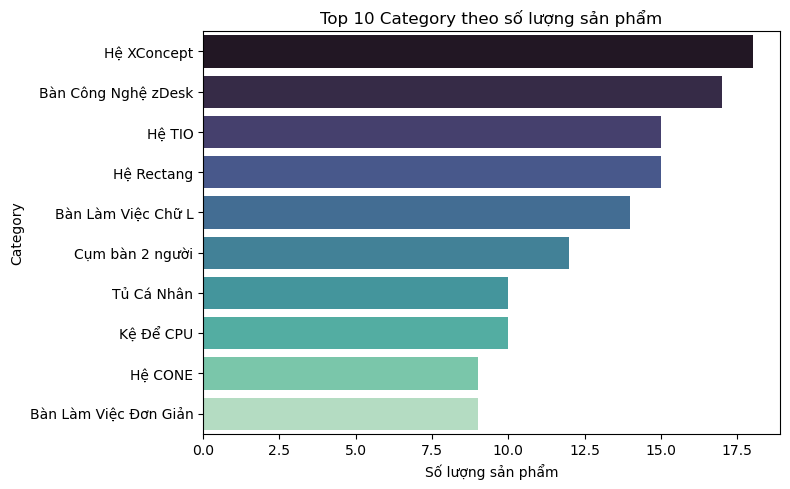

In [19]:
top_categories = df['category'].value_counts().head(10)
print("Top 10 category phổ biến nhất (trên tổng", df['category'].nunique(), "category):")
print(top_categories)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(y=top_categories.index, x=top_categories.values, palette='mako', ax=ax)
ax.set_title('Top 10 Category theo số lượng sản phẩm')
ax.set_xlabel('Số lượng sản phẩm')
ax.set_ylabel('Category')
plt.tight_layout()
plt.show()


sentiment
Negative    140
Positive    124
Neutral      72
Name: count, dtype: int64
sentiment
Negative    41.7 %
Positive    36.9 %
Neutral     21.4 %
Name: count, dtype: object


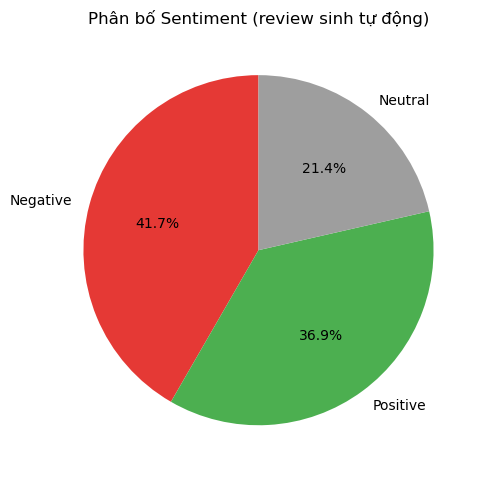

In [20]:
sent_counts = df['sentiment'].value_counts()
print(sent_counts)
print((sent_counts / sent_counts.sum() * 100).round(1).astype(str) + ' %')

fig, ax = plt.subplots(figsize=(5, 5))
colors = {'Positive': '#4caf50', 'Negative': '#e53935', 'Neutral': '#9e9e9e'}
ax.pie(sent_counts.values, labels=sent_counts.index, autopct='%1.1f%%',
       colors=[colors.get(c, '#888') for c in sent_counts.index], startangle=90)
ax.set_title('Phân bố Sentiment (review sinh tự động)')
plt.tight_layout()
plt.show()


**So what?** Dữ liệu có 98 category rất phân mảnh (nhiều category chỉ 1-2 sản phẩm) — nên gộp lại thành nhóm lớn hơn (bàn làm việc, bàn họp, phụ kiện...) trước khi đưa vào mô hình phân loại để tránh sparsity. Sentiment gần như cân bằng giữa Positive/Negative/Neutral (không lệch nhãn nặng), phù hợp để huấn luyện mô hình phân loại sentiment mà không cần class-weighting mạnh.

## 5. Multivariate Analysis

### 5.1 Numerical vs Numerical — Correlation Matrix

            price_vnd  rating_num  length_cm  width_cm  height_cm
price_vnd        1.00        0.10       0.42      0.26       0.36
rating_num       0.10        1.00       0.01      0.03       0.05
length_cm        0.42        0.01       1.00      0.62      -0.16
width_cm         0.26        0.03       0.62      1.00      -0.16
height_cm        0.36        0.05      -0.16     -0.16       1.00


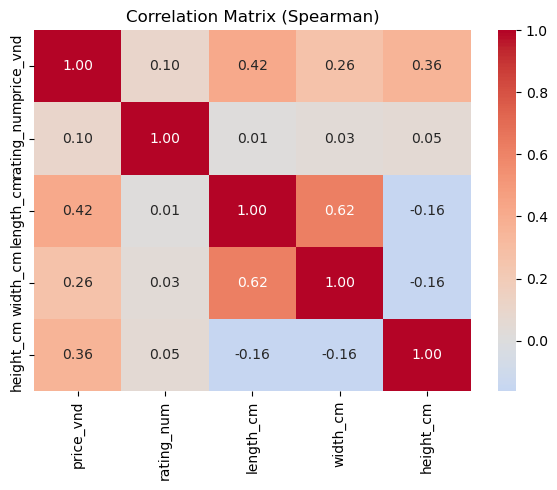

In [21]:
num_cols = ['price_vnd', 'rating_num', 'length_cm', 'width_cm', 'height_cm']
corr = df[num_cols].corr(method='spearman')
print(corr.round(2))

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation Matrix (Spearman)')
plt.tight_layout()
plt.show()


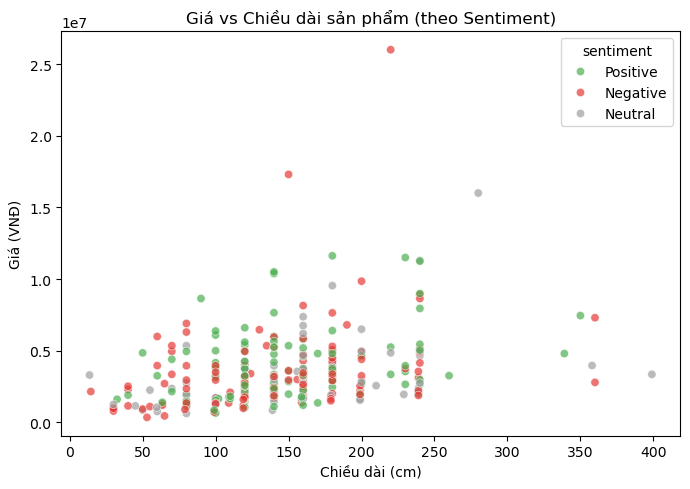

In [22]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x='length_cm', y='price_vnd', hue='sentiment',
                 palette={'Positive': '#4caf50', 'Negative': '#e53935', 'Neutral': '#9e9e9e'}, alpha=0.7, ax=ax)
ax.set_title('Giá vs Chiều dài sản phẩm (theo Sentiment)')
ax.set_xlabel('Chiều dài (cm)')
ax.set_ylabel('Giá (VNĐ)')
plt.tight_layout()
plt.show()


**So what?** `length_cm` có tương quan dương vừa phải với `price_vnd` (bàn dài hơn => đắt hơn), hợp lý về mặt vật liệu. `rating_num` gần như không tương quan với giá — nghĩa là giá không phải yếu tố quyết định đánh giá sản phẩm tốt/xấu trong review sinh tự động, mô hình dự đoán rating nên dựa vào nội dung review (text feature) hơn là giá.

### 5.2 Categorical vs Numerical

category
Hệ TIO                 5.114667e+06
Bàn Làm Việc Chữ L     5.026429e+06
Bàn Công Nghệ zDesk    3.418235e+06
Hệ XConcept            3.223889e+06
Hệ Rectang             2.880667e+06
Name: price_vnd, dtype: float64


C:\Users\ACER\AppData\Local\Temp\ipykernel_22876\1742486998.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=avg_price_cat.values, y=avg_price_cat.index, palette='crest', ax=ax)


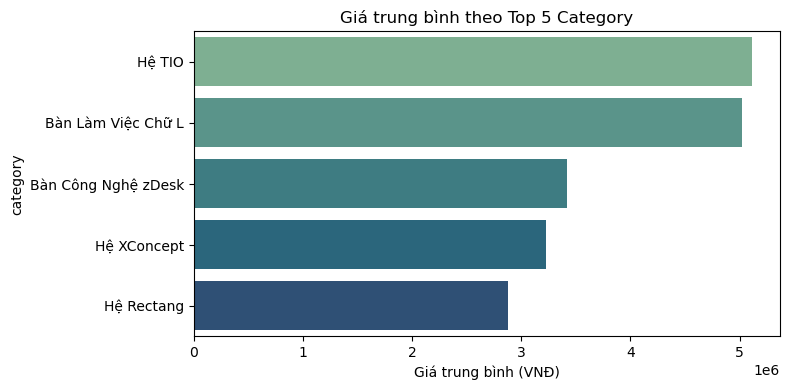

In [23]:
top5_cat = df['category'].value_counts().head(5).index
avg_price_cat = df[df['category'].isin(top5_cat)].groupby('category')['price_vnd'].mean().sort_values(ascending=False)
print(avg_price_cat)

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=avg_price_cat.values, y=avg_price_cat.index, palette='crest', ax=ax)
ax.set_title('Giá trung bình theo Top 5 Category')
ax.set_xlabel('Giá trung bình (VNĐ)')
plt.tight_layout()
plt.show()


C:\Users\ACER\AppData\Local\Temp\ipykernel_22876\3800963698.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sentiment', y='price_vnd',


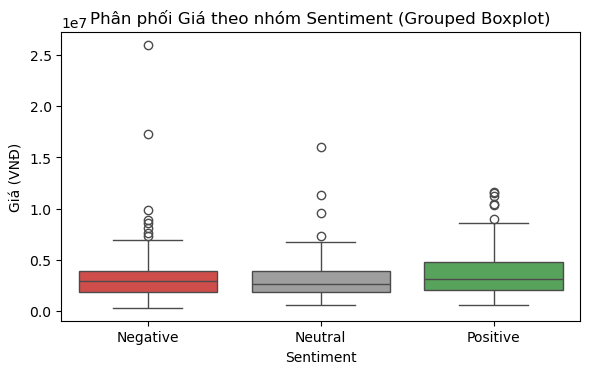

In [24]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='sentiment', y='price_vnd',
            order=['Negative', 'Neutral', 'Positive'], palette=colors, ax=ax)
ax.set_title('Phân phối Giá theo nhóm Sentiment (Grouped Boxplot)')
ax.set_xlabel('Sentiment')
ax.set_ylabel('Giá (VNĐ)')
plt.tight_layout()
plt.show()


**So what?** Giá trung bình khác biệt rõ giữa các category (Top 5) — category có thể dùng làm feature phân tầng giá mạnh. Phân phối giá theo sentiment gần như chồng lấn nhau (median tương tự) → xác nhận lại insight ở trên: giá **không phải** nguyên nhân chính khiến khách hàng đánh giá tích cực/tiêu cực trong review sinh tự động này.

### 5.3 Categorical vs Categorical

sentiment            Negative  Neutral  Positive
category                                        
Bàn Công Nghệ zDesk         5        4         8
Bàn Làm Việc Chữ L          3        6         5
Hệ Rectang                  9        2         4
Hệ TIO                      8        3         4
Hệ XConcept                 7        1        10


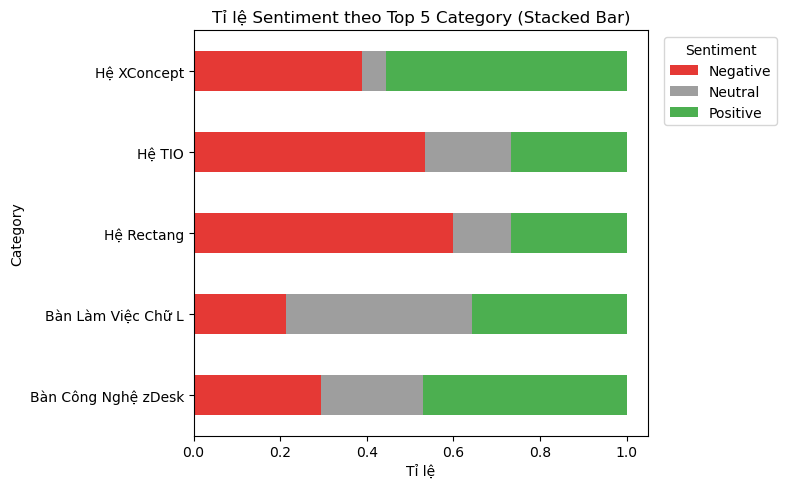

In [25]:
top5_cat_df = df[df['category'].isin(top5_cat)]
ctab = pd.crosstab(top5_cat_df['category'], top5_cat_df['sentiment'])
print(ctab)

fig, ax = plt.subplots(figsize=(8, 5))
ctab_pct = ctab.div(ctab.sum(axis=1), axis=0)
ctab_pct.plot(kind='barh', stacked=True, ax=ax,
              color=[colors.get(c, '#888') for c in ctab_pct.columns])
ax.set_title('Tỉ lệ Sentiment theo Top 5 Category (Stacked Bar)')
ax.set_xlabel('Tỉ lệ')
ax.set_ylabel('Category')
ax.legend(title='Sentiment', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


**So what?** Tỉ lệ Positive/Negative/Neutral khá đồng đều giữa các category lớn — cho thấy sentiment trong review được LLM sinh ra **ngẫu nhiên độc lập** với category sản phẩm, chứ không phản ánh chất lượng thật của từng dòng sản phẩm. Đây là điểm cần lưu ý khi dùng bộ `generated_review`/`sentiment` này để huấn luyện mô hình: nhãn sentiment mang tính tổng hợp (synthetic), không nên diễn giải như đánh giá thực tế của khách hàng.

## 6. Tổng kết Final_Data sau EDA

In [26]:
final_data = df.copy()
print(final_data.isnull().sum())
print(final_data.head(5).to_string())


product_id          0
product_name        0
product_price       0
category            0
dimensions          0
product_url         0
generated_review    0
rating              0
sentiment           0
price_vnd           0
rating_num          0
length_cm           0
width_cm            0
height_cm           0
dtype: int64
  product_id                                                         product_name product_price            category                                  dimensions                                                                                    product_url                                                                                                                                                                                                                                                                                                                                                                                                                                         

In [27]:
import json
data = json.loads(
    final_data.to_json(
        orient="records",
        force_ascii=False
    )
)

with open("clean_data.json", "w", encoding="utf-8") as f:
    json.dump(data, f, ensure_ascii=False, indent=2)